# How well calibrated is a public sports forecasting model?

This notebook is a quick tour of the **Sports Match Forecasts vs Results** dataset. Every row is one finished match: the
[Forepitch](https://forepitch.com/) model's last probabilities before kick-off and what actually happened.

We look at:
1. what is in the data;
2. how often the most likely outcome happened, compared with simple baselines;
3. **calibration**: when the model says 60%, does it happen 60% of the time?
4. Brier score and log loss for football;
5. how results differ between competitions.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find(name):
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) or glob.glob(name) or glob.glob(f'../data/{name}')
    return hits[0]

df = pd.read_csv(find('forepitch-record.csv'), parse_dates=['kickoff_utc', 'estimate_utc'])
comps = pd.read_csv(find('competitions.csv'))
print(df.shape)
df.head()

(6849, 16)


,kickoff_utc,estimate_utc,sport,competition,home,away,p_home,p_draw,p_away,pick,pick_p,likely_score,final_score,pick_hit,score_hit,url
0,2026-09-28 13:30:00+00:00,2026-09-28 13:16:32+00:00,hockey,KHL,Avangard Omsk,Magnitogorsk,0.4036,0.2168,0.3796,h,0.5117,4:1,1:5,0,0.0,https://forepitch.com/hockey/match/avangard-om...
1,2026-09-28 16:00:00+00:00,2026-09-28 15:29:44+00:00,football,UNL,Georgia,Ukraine,0.2705,0.2674,0.4621,a,0.4621,1:2,0:0,0,0.0,https://forepitch.com/football/match/georgia-u...
2,2026-09-28 16:00:00+00:00,2026-09-28 14:33:08+00:00,football,UNL,Armenia,Montenegro,0.3060,0.2654,0.4287,a,0.4287,1:2,2:3,1,0.0,https://forepitch.com/football/match/armenia-m...
3,2026-09-28 16:00:00+00:00,2026-09-28 14:02:20+00:00,football,UNL,Latvia,Cyprus,0.3582,0.2885,0.3533,h,0.3582,1:0,0:0,0,0.0,https://forepitch.com/football/match/latvia-cy...
4,2026-09-28 16:10:00+00:00,2026-09-28 14:12:27+00:00,hockey,KHL,Dinamo Minsk,Lada,0.7156,0.1524,0.1320,h,0.8241,4:1,5:4,1,0.0,https://forepitch.com/hockey/match/dinamo-mins...


## 1. What is in the data

In [2]:
summary = (df.groupby('sport')
             .agg(matches=('pick_hit', 'size'), first=('kickoff_utc', 'min'), last=('kickoff_utc', 'max'),
                  pick_hit=('pick_hit', 'mean'))
             .sort_values('matches', ascending=False))
summary['pick_hit'] = (summary['pick_hit'] * 100).round(1)
summary

,matches,first,last,pick_hit
sport,,,,
football,3238,2026-09-28 16:00:00+00:00,2026-11-17 19:45:00+00:00,53.2
hockey,1539,2026-09-28 13:30:00+00:00,2026-11-17 18:30:00+00:00,60.1
tennis,987,2026-09-29 02:10:00+00:00,2026-11-17 13:10:00+00:00,64.2
basketball,663,2026-10-06 23:30:00+00:00,2026-11-17 19:45:00+00:00,69.7
volleyball,369,2026-10-16 12:00:00+00:00,2026-11-17 16:00:00+00:00,81.3
mma,53,2026-10-24 14:00:00+00:00,2026-11-15 02:00:00+00:00,64.2


Football and hockey have three outcomes (home, draw, away; hockey in regulation time). The other sports have
two, so `p_draw` is empty there. Note that a higher hit rate in, say, volleyball does not mean a better model: two-way
matches with clear favourites are simply easier to call. That is why calibration matters more than hit rate.

## 2. Football: the most likely outcome against simple baselines

In [3]:
fb = df[df.sport == 'football'].copy()
a, b = fb.final_score.str.split(':', expand=True).astype(int).T.values
fb['result'] = np.select([a > b, a < b], ['h', 'a'], 'd')

base = fb.result.value_counts(normalize=True)
print(f"Matches: {len(fb)}")
print(f"Model's most likely outcome happened: {fb.pick_hit.mean():.1%}")
print(f"Always pick the home side:            {base['h']:.1%}")
print(f"Exact most likely score happened:     {fb.score_hit.mean():.1%}")

Matches: 3238
Model's most likely outcome happened: 53.2%
Always pick the home side:            43.5%
Exact most likely score happened:     9.9%


## 3. Calibration

For every football match the model gives three probabilities. We pool all of them (home, draw and away for every
match), bin them, and compare the average forecast in each bin with how often that outcome actually happened. A
perfectly calibrated model sits on the diagonal.

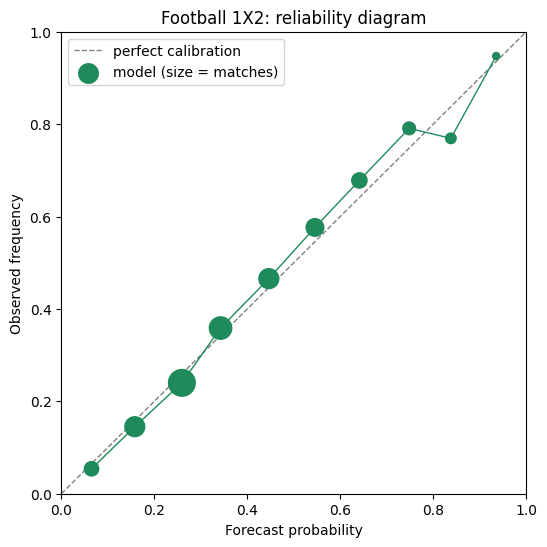

,forecast,observed,n
bin,,,
"(0.0, 0.1]",0.065,0.054,315
"(0.1, 0.2]",0.158,0.145,1151
"(0.2, 0.3]",0.259,0.240,3788
"(0.3, 0.4]",0.342,0.359,1860
"(0.4, 0.5]",0.446,0.466,1160
"(0.5, 0.6]",0.546,0.576,727
"(0.6, 0.7]",0.641,0.678,407
"(0.7, 0.8]",0.748,0.791,196
"(0.8, 0.9]",0.838,0.769,91


In [4]:
rows = []
for k, col in [('h', 'p_home'), ('d', 'p_draw'), ('a', 'p_away')]:
    rows.append(pd.DataFrame({'p': fb[col], 'hit': (fb.result == k).astype(int)}))
pool = pd.concat(rows)
pool['bin'] = pd.cut(pool.p, np.linspace(0, 1, 11))
cal = pool.groupby('bin', observed=True).agg(forecast=('p', 'mean'), observed=('hit', 'mean'), n=('hit', 'size'))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], ls='--', c='grey', lw=1, label='perfect calibration')
ax.scatter(cal.forecast, cal.observed, s=np.sqrt(cal.n) * 6, c='#1f8a5b', zorder=3, label='model (size = matches)')
ax.plot(cal.forecast, cal.observed, c='#1f8a5b', lw=1)
ax.set(xlabel='Forecast probability', ylabel='Observed frequency', xlim=(0, 1), ylim=(0, 1),
       title='Football 1X2: reliability diagram')
ax.legend(loc='upper left')
plt.show()
cal.round(3)

Calibration of the single most likely outcome, for every sport:

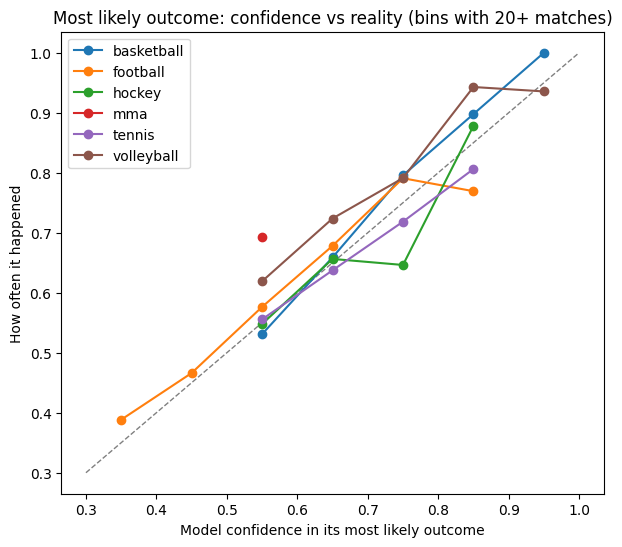

In [5]:
df['conf'] = pd.cut(df.pick_p, [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
tab = df.groupby(['sport', 'conf'], observed=True).pick_hit.agg(['mean', 'size'])
tab = tab[tab['size'] >= 20]

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0.3, 1], [0.3, 1], ls='--', c='grey', lw=1)
for sport, g in tab.groupby(level=0):
    mids = [iv.mid for iv in g.index.get_level_values(1)]
    ax.plot(mids, g['mean'], marker='o', label=sport)
ax.set(xlabel='Model confidence in its most likely outcome', ylabel='How often it happened',
       title='Most likely outcome: confidence vs reality (bins with 20+ matches)')
ax.legend()
plt.show()

## 4. Brier score and log loss (football)

Both are lower-is-better. As a baseline we use the overall frequency of home wins, draws and away wins in the same
matches: a "model" that knows nothing about the teams.

In [6]:
P = fb[['p_home', 'p_draw', 'p_away']].to_numpy()
Y = pd.get_dummies(fb.result)[['h', 'd', 'a']].to_numpy().astype(float)
B = np.tile(base[['h', 'd', 'a']].to_numpy(), (len(fb), 1))

def brier(p): return ((p - Y) ** 2).sum(axis=1).mean()
def logloss(p): return -np.log((p * Y).sum(axis=1).clip(1e-12)).mean()

pd.DataFrame({'Brier score': [brier(P), brier(B)], 'Log loss': [logloss(P), logloss(B)]},
             index=['Model', 'Base rates']).round(4)

,Brier score,Log loss
Model,0.5799,0.9738
Base rates,0.6476,1.0700


## 5. By competition (football, 40+ matches)

In [7]:
by = (fb.groupby('competition')
        .agg(matches=('pick_hit', 'size'), pick_hit=('pick_hit', 'mean'), score_hit=('score_hit', 'mean'))
        .query('matches >= 40')
        .join(comps[comps.sport == 'football'].set_index('competition')[['name', 'country']])
        .sort_values('pick_hit', ascending=False))
by[['pick_hit', 'score_hit']] = (by[['pick_hit', 'score_hit']] * 100).round(1)
by

,matches,pick_hit,score_hit,name,country
competition,,,,,
CDR,50,76.0,6.0,Copa del Rey,Spain
UCL,54,70.4,5.6,UEFA Champions League,Europe
BLR,45,68.9,8.9,Belarusian Premier League,Belarus
TUR,45,68.9,11.1,Turkish Super Lig,Turkey
SERIEA,60,66.7,13.3,Serie A,Italy
LIGUE1,45,64.4,11.1,Ligue 1,France
BRA,64,64.1,17.2,Brazilian Serie A,Brazil
LALIGA,50,64.0,12.0,La Liga,Spain
POL,46,60.9,13.0,Polish Ekstraklasa,Poland


## Ideas for further work

- Compare these probabilities with your own model on the same matches.
- Compute the ranked probability score (RPS), which respects the order home > draw > away.
- Check whether calibration changes with how long before kick-off the estimate was made (`estimate_utc`).

The live file, updated daily, is at https://forepitch.com/data/forepitch-record.csv, and accuracy by sport and
league is at https://forepitch.com/accuracy/.